# Notebook 03 - Machine Learning (Prédiction de l'Adoption)

## Objectif

Ce notebook utilise des algorithmes de Machine Learning (Scikit-learn) pour prédire l'intention d'achat (`buy_intent`) et le prix acceptable (`ideal_price`), répondant aux questions clés posées par l'étude.

En analysant les patterns économiques et démographiques, nous cherchons des **insights actionnables** pour transformer l'intention d'achat (92,5%) en adoption réelle.

## Méthodologie

L'analyse se déroule en **4 axes** structurés, chacun associé à des modèles ML, métriques et interprétations statistiques.

## Navigation

| Étape | Thème | Description |
|-------|-------|-------------|
| 1 | Features vs Target | Vérification du pouvoir discriminant des variables |
| 2 | Classification | Prédiction de l'intention d'achat (buy_intent) |
| 3 | Régression | Estimation du prix acceptable (ideal_price) |
| 4 | Interprétation | Identification des variables clés (Feature Importance) |

---
*Note : Nous utilisons Random Forest pour sa robustesse aux relations non-linéaires et sa performance sur les petits jeux de données (n=106).*

## 🗺️ 2. Le Plan du Notebook

🟢 **ÉTAPE 1** | Importation et chargement de la base

🟡 **ÉTAPE 2** | Préparation et modèle de classification (buy_intent)

🔴 **ÉTAPE 3** | Modèle de régression pour le prix acceptable (ideal_price)

🟣 **ÉTAPE 4** | Interprétation : Feature Importance

# ÉTAPE 1 | Importation et chargement de la base clean

Ce notebook utilise la base préparée lors des étapes précédentes. Nous chargons le fichier CSV nettoyé contenant 106 observations et 19 variables pertinentes pour la modélisation.

# 1. IMPORTATION ET CHARGEMENT DE LA BASSE DE DONNÉE clean

In [2]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

df = pd.read_csv(project_root / "data" / "processed" / "base_femmes_2024_clean.csv")

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 6)

print(f"✅ Dataset chargé : {df.shape}")
display(df.head(20))

✅ Dataset chargé : (106, 19)


,respondent_id,age,income,is_financially_dependent,household_income,education,is_pregnant,has_child_under_5,num_children,num_children_outlier,num_children_missing,ideal_price,ideal_price_missing,ideal_price_imputed,price_corrected,low_price_respondent,buy_intent,perceived_child_benefit,perceived_child_benefit_missing
0,364479596,29,200000,0,350000,Supérieur,0,1,1.0,0,0,2000.0,0,0,0,0,1,1.0,0
1,364482210,26,50000,0,50000,Supérieur,0,1,1.0,0,0,1500.1,0,0,1,0,1,1.0,0
2,364504312,21,50000,0,250000,Supérieur,0,1,1.0,0,0,1500.0,0,0,0,0,1,1.0,0
3,364721648,22,15000,0,30000,Secondaire,0,1,2.0,0,0,200.0,0,0,0,1,1,1.0,0
4,364729224,30,15000,0,50000,Secondaire,0,1,2.0,0,0,1300.0,1,1,0,0,1,1.0,0
5,364732937,40,15000,0,50000,Primaire,0,1,2.0,0,0,1000.0,0,0,0,0,1,1.0,0
6,364739013,30,20000,0,50000,Secondaire,0,1,1.0,0,0,1100.0,0,0,0,0,1,1.0,0
7,364745343,30,30000,0,200000,Secondaire,0,1,1.0,0,0,1000.0,0,0,0,0,1,1.0,0
8,364759964,30,20000,0,30000,Secondaire,0,1,1.0,0,0,1000.0,0,0,0,0,1,1.0,0
9,365926379,18,0,1,0,Supérieur,0,1,1.0,0,0,1200.0,0,0,0,0,1,1.0,0


# 🗺️ 2. Le Plan du Notebook 

🟢 **Étape 1** : Vérification des Features vs Target

🟡 **Étape 2** : Préparation et Modèle de Classification (buy_intent)

🔴 **Étape 3** : Modèle de Régression (ideal_price)

🟣 **Étape 4** : L'Interprétation (Feature Importance)

# ETAPE 1: VÉRIFICATION DES FEATURES VS TARGET

Le but de cette étape est de voir si les variables ont un pouvoir discriminant.

### Prompt pour OPENCODE

Génère UNIQUEMENT le code Python (avec Pandas) pour analyser la relation entre les features et la cible buy_intent. Le code doit : 
1) Afficher un tableau des moyennes et médianes pour (age, income, household_income, ideal_price, num_children) groupées par buy_intent.
2) Afficher un pd.crosstab normalisé (en %) croisant education et buy_intent.

Ajoute des commentaires bilingues (EN/FR).

In [3]:
# EN: Validate required columns exist
# FR: Validation de l'existence des colonnes requises
required_cols = [
    "buy_intent", "age", "income", "household_income", "ideal_price",
    "num_children", "education",
]
missing = [c for c in required_cols if c not in df.columns]
assert not missing, f"EN: Missing columns: {missing}\nFR: Colonnes manquantes : {missing}"
assert df["buy_intent"].isin([0, 1]).all(), "EN: buy_intent must be binary 0/1\nFR: buy_intent doit être binaire 0/1"

# ==================================================================
# 1) Means and medians of numeric features grouped by buy_intent
# ==================================================================
# EN: 1) Moyennes et médianes des variables numériques groupées par buy_intent
# FR: 1) Moyennes et médianes des variables numériques groupées par buy_intent
numeric_cols = ["age", "income", "household_income", "ideal_price", "num_children"]

grouped = (
    df.groupby("buy_intent")[numeric_cols]
    .agg(["mean", "median"])
    .round(2)
)

# EN: Rename index labels for readability
# FR: Renommage des libellés d'index pour la lisibilité
grouped.index = grouped.index.map({0: "No (0)", 1: "Yes (1)"})

print("EN: Means and medians by buy_intent\nFR: Moyennes et médianes par buy_intent")
print(grouped)
print()

# ==================================================================
# 2) Normalized crosstab (row %) of education vs buy_intent
# ==================================================================
# EN: 2) Crosstab normalisé (pourcentage de ligne) de education vs buy_intent
# FR: 2) Crosstab normalisé (pourcentage de ligne) de education vs buy_intent
ct = pd.crosstab(df["education"], df["buy_intent"], normalize="index") * 100

# EN: Ensure both buy_intent columns exist
# FR: S'assurer que les deux colonnes buy_intent existent
for col in [0, 1]:
    if col not in ct.columns:
        ct[col] = 0.0
ct = ct[[0, 1]]

# EN: Rename columns and index for readability
# FR: Renommage des colonnes et index pour la lisibilité
ct.columns = ["Buy intent: No (0)", "Buy intent: Yes (1)"]
ct.index.name = "Education level"
ct = ct.round(1)

print("EN: Crosstab education vs buy_intent (row %)\nFR: Crosstab education vs buy_intent (% de ligne)")
print(ct)

# EN: Assertions: both outputs are non-empty
# FR: Assertions : les deux résultats sont non vides
assert not grouped.empty, "EN: Grouped table is empty\nFR: Table groupée vide"
assert not ct.empty, "EN: Crosstab is empty\nFR: Crosstab vide"

EN: Means and medians by buy_intent
FR: Moyennes et médianes par buy_intent
              age           income          household_income            \
             mean median      mean   median             mean    median   
buy_intent                                                               
No (0)      20.50   18.5   9250.00   7500.0        130000.00   72500.0   
Yes (1)     26.03   26.0  39132.65  21500.0        164438.78  150000.0   

           ideal_price         num_children         
                  mean  median         mean median  
buy_intent                                          
No (0)         1187.50  1300.0         1.60    2.0  
Yes (1)        1211.23  1300.0         1.82    2.0  

EN: Crosstab education vs buy_intent (row %)
FR: Crosstab education vs buy_intent (% de ligne)
                 Buy intent: No (0)  Buy intent: Yes (1)
Education level                                         
Aucun                           0.0                100.0
Primaire             

**Interprètation**

L'analyse comparative des profils selon l'intention d'achat (`buy_intent`) révèle des dynamiques intéressantes :
1. **Le revenu est le facteur le plus discriminant** : Les femmes qui déclarent vouloir acheter ont un revenu personnel moyen nettement supérieur (39 132 FCFA) à celles qui refusent (9 250 FCFA). Le revenu du ménage suit la même tendance.
2. **L'âge influence légèrement** : Les acheteuses potentielles sont un peu plus âgées (moyenne de 26 ans vs 20,5 ans pour les refus).
3. **Le prix idéal n'est pas un bon prédicteur** : Les moyennes de `ideal_price` sont quasi identiques (1187 vs 1211). Le prix qu'une femme est prête à payer ne détermine pas son intention d'achat.
4. **L'éducation apporte une nuance inattendue** : Les femmes ayant un niveau "Supérieur" ont le taux de refus le plus élevé (25 %). À l'inverse, les niveaux Primaire et Secondaire affichent une adhésion quasi-totale (>89 %). Mais nous nous attendons au contraire. Serait-ce une malcompréhension du rôle du produit vis à vis des femmes de niveau supérieur ou qu'elles fixent uniquement son rôle bénéfique pour leur enfant, cela pourrait justifier le refus, mais nous ne pouvons pas l'affirmer.

# ÉTAPE 2 | Préparation et modèle de classification (buy_intent)

On prépare les données, on les coupe en Train/Test, et on entraîne le modèle Random Forest pour prédire l'intention d'achat.

### Prompt pour OPENCODE

### Prompt 1
Génère le code python pour préparer les données pour la classification.
1) Encode education avec pd.get_dummies(drop_first=True).
2) Définis X en retirant respondent_id, buy_intent, et surtout ideal_price (pour éviter la fuite de données, car on ne connaît pas le prix idéal avant l'achat), ainsi que les colonnes de traçabilité.
3) Définis y = buy_intent.
4) Fais un train_test_split (test_size=0.2, random_state=42, stratify=y).

Affiche les shapes.

In [7]:
from sklearn.model_selection import train_test_split
# EN: Validate required columns exist
# FR: Validation de l'existence des colonnes requises
required_cols = [
    "respondent_id", "age", "income", "is_financially_dependent",
    "household_income", "education", "is_pregnant", "has_child_under_5",
    "num_children", "num_children_outlier", "num_children_missing",
    "ideal_price", "ideal_price_missing", "price_corrected",
    "low_price_respondent", "buy_intent",
    "perceived_child_benefit", "perceived_child_benefit_missing",
]
missing = [c for c in required_cols if c not in df.columns]
assert not missing, f"EN: Missing columns: {missing}\nFR: Colonnes manquantes : {missing}"
assert df["buy_intent"].isin([0, 1]).all(), "EN: buy_intent must be binary 0/1\nFR: buy_intent doit être binaire 0/1"

# EN: Work on a copy to avoid modifying the cleaned dataset
# FR: Travail sur une copie pour ne pas modifier le jeu nettoyé
df_model = df.copy()

# EN: Fill structural NaN in num_children with 0 (no child < 5 => 0 children)
# FR: Remplit les NaN structurels de num_children par 0 (pas d'enfant <5 => 0 enfants)
df_model["num_children"] = df_model["num_children"].fillna(0)

# EN: Fill NaN in perceived_child_benefit with 0 (not applicable => no perceived benefit)
# FR: Remplit les NaN de perceived_child_benefit par 0 (non applicable => aucun bénéfice perçu)
df_model["perceived_child_benefit"] = df_model["perceived_child_benefit"].fillna(0)

# EN: Drop identifier, target, leakage-prone and traceability columns
# FR: Supprime identifiant, cible, colonnes sujettes à la fuite de données et colonnes de traçabilité
drop_cols = [
    "respondent_id",            # EN: traceability key / FR: clé de traçabilité
    "buy_intent",               # EN: target variable / FR: variable cible
    "ideal_price",              # EN: data leakage — ideal price unknown before purchase / FR: fuite de données — prix idéal inconnu avant l'achat
    "price_corrected",          # EN: traceability indicator / FR: indicateur de traçabilité
    "low_price_respondent",     # EN: derived from ideal_price (leakage risk) / FR: dérivé de ideal_price (risque de fuite)
    "num_children_outlier",     # EN: traceability indicator / FR: indicateur de traçabilité
    "num_children_missing",     # EN: traceability indicator / FR: indicateur de traçabilité
    "ideal_price_missing",      # EN: traceability indicator / FR: indicateur de traçabilité
    "perceived_child_benefit_missing",  # EN: traceability indicator / FR: indicateur de traçabilité
]
X_raw = df_model.drop(columns=drop_cols)

# EN: Assert education column is present for encoding
# FR: Assertion que la colonne education est présente pour l'encodage
assert "education" in X_raw.columns, "EN: education column missing after drop\nFR: Colonne education manquante après suppression"

# EN: One-hot encode education (drop first category to avoid multicollinearity)
# FR: Encodage one-hot de education (suppression de la première catégorie pour éviter la multicolinéarité)
X = pd.get_dummies(X_raw, columns=["education"], drop_first=True, dtype=int)

# EN: Define target vector
# FR: Définition du vecteur cible
y = df_model["buy_intent"].astype(int)

# EN: Assertions before split
# FR: Assertions avant le split
assert X.shape[0] == len(y), "EN: X and y row count mismatch\nFR: Incohérence du nombre de lignes entre X et y"
assert y.nunique() == 2, "EN: y must contain both classes (0 and 1)\nFR: y doit contenir les deux classes (0 et 1)"
assert X.isna().sum().sum() == 0, "EN: X contains NaN values\nFR: X contient des valeurs NaN"

# EN: Train/test split stratified on y
# FR: Split train/test stratifié sur y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# EN: Display shapes
# FR: Affichage des formes
print("EN: Data shapes after preparation\nFR: Formes des données après préparation")
print(f"X shape      : {X.shape}")
print(f"y shape      : {y.shape}")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape : {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape : {y_test.shape}")
print()
print("EN: Class distribution in y_train\nFR: Répartition des classes dans y_train")
print(y_train.value_counts(normalize=True).round(3))
print()
print("EN: Class distribution in y_test\nFR: Répartition des classes dans y_test")
print(y_test.value_counts(normalize=True).round(3))

# EN: Final assertions on split integrity
# FR: Assertions finales sur l'intégrité du split
assert X_train.shape[1] == X_test.shape[1], "EN: Feature column mismatch between train and test\nFR: Incohérence des colonnes de features entre train et test"
assert set(y_train.unique()) == {0, 1}, "EN: y_train missing a class\nFR: y_train manque une classe"
assert set(y_test.unique()) == {0, 1}, "EN: y_test missing a class\nFR: y_test manque une classe"

EN: Data shapes after preparation
FR: Formes des données après préparation
X shape      : (106, 12)
y shape      : (106,)
X_train shape: (84, 12)
X_test shape : (22, 12)
y_train shape: (84,)
y_test shape : (22,)

EN: Class distribution in y_train
FR: Répartition des classes dans y_train
buy_intent
1    0.929
0    0.071
Name: proportion, dtype: float64

EN: Class distribution in y_test
FR: Répartition des classes dans y_test
buy_intent
1    0.909
0    0.091
Name: proportion, dtype: float64


### Prompt 2:
Génère le code pour entraîner un RandomForestClassifier.
1) Initialise le modèle avec n_estimators=100, random_state=42 et class_weight='balanced' (pour compenser le déséquilibre de la cible).
2) Entraîne-le sur X_train et y_train.
3) Fais les prédictions sur X_test.
4) Affiche l'accuracy, le classification_report complet et la matrice de confusion (avec ConfusionMatrixDisplay de Scikit-learn).

Ajoute des commentaires bilingues.

EN: Accuracy on test set: 0.9091
FR: Accuracy sur le jeu de test : 0.9091

EN: Classification report
FR: Rapport de classification
              precision    recall  f1-score   support

      No (0)       0.00      0.00      0.00         2
     Yes (1)       0.91      1.00      0.95        20

    accuracy                           0.91        22
   macro avg       0.45      0.50      0.48        22
weighted avg       0.83      0.91      0.87        22


EN: Confusion matrix (raw counts)
FR: Matrice de confusion (effectifs bruts)
[[ 0  2]
 [ 0 20]]


/home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined 

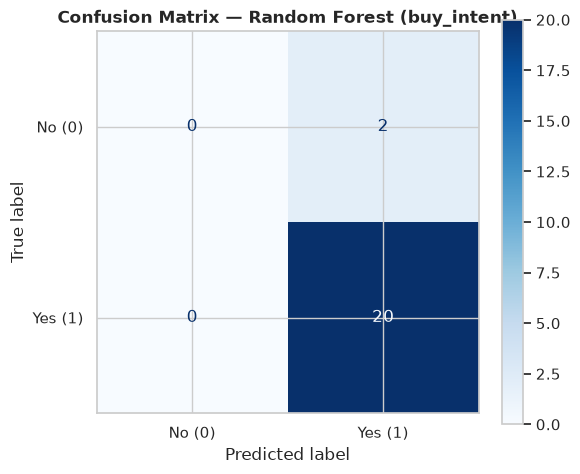


EN: Confusion matrix figure saved to /home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/reports/figures/fig07_confusion_matrix_rf.png
FR: Figure de matrice de confusion enregistrée dans /home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/reports/figures/fig07_confusion_matrix_rf.png


In [8]:
# EN: Train Random Forest classifier to predict buy_intent
# FR: Entraînement d'un Random Forest pour prédire buy_intent
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
# EN: Validate that train/test splits exist in memory
# FR: Validation que les splits train/test existent en mémoire
for var_name, var in [("X_train", X_train), ("X_test", X_test), ("y_train", y_train), ("y_test", y_test)]:
    assert var is not None, f"EN: {var_name} is not defined — run the data preparation cell first\nFR: {var_name} n'est pas défini — exécutez d'abord la cellule de préparation des données"

assert X_train.shape[1] == X_test.shape[1], "EN: Feature column mismatch between train and test\nFR: Incohérence des colonnes de features entre train et test"
assert set(y_train.unique()) == {0, 1}, "EN: y_train must contain both classes\nFR: y_train doit contenir les deux classes"
assert set(y_test.unique()) == {0, 1}, "EN: y_test must contain both classes\nFR: y_test doit contenir les deux classes"

# EN: Initialize Random Forest classifier
#   - n_estimators=100 : number of trees
#   - random_state=42 : reproducibility
#   - class_weight='balanced' : compensate for class imbalance (98 Yes vs 8 No)
# FR: Initialisation du classifieur Random Forest
#   - n_estimators=100 : nombre d'arbres
#   - random_state=42 : reproductibilité
#   - class_weight='balanced' : compense le déséquilibre de classes (98 Oui vs 8 Non)
rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")

# EN: Train the model on the training set
# FR: Entraînement du modèle sur le jeu d'entraînement
rf.fit(X_train, y_train)

# EN: Predict on the test set
# FR: Prédictions sur le jeu de test
y_pred = rf.predict(X_test)

# EN: Compute accuracy
# FR: Calcul de l'accuracy
acc = accuracy_score(y_test, y_pred)
print(f"EN: Accuracy on test set: {acc:.4f}\nFR: Accuracy sur le jeu de test : {acc:.4f}")

# EN: Print full classification report
# FR: Affichage du rapport de classification complet
print("\nEN: Classification report\nFR: Rapport de classification")
print(classification_report(y_test, y_pred, target_names=["No (0)", "Yes (1)"]))

# EN: Confusion matrix
# FR: Matrice de confusion
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print("\nEN: Confusion matrix (raw counts)\nFR: Matrice de confusion (effectifs bruts)")
print(cm)

# EN: Plot confusion matrix with ConfusionMatrixDisplay
# FR: Affichage de la matrice de confusion avec ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No (0)", "Yes (1)"])
disp.plot(ax=ax, cmap="Blues", colorbar=True, values_format="d")
ax.set_title("Confusion Matrix — Random Forest (buy_intent)", fontsize=12, fontweight="bold")
plt.tight_layout()
display(fig)

# EN: Save confusion matrix figure
# FR: Sauvegarde de la figure de la matrice de confusion
fig_dir = project_root / "reports" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
cm_path = fig_dir / "fig07_confusion_matrix_rf.png"
fig.savefig(cm_path, dpi=150, bbox_inches="tight")
plt.close(fig)

# EN: Assertions
# FR: Assertions
assert 0 <= acc <= 1, "EN: Accuracy out of bounds\nFR: Accuracy hors bornes"
assert cm_path.is_file(), f"EN: Confusion matrix figure not saved at {cm_path}\nFR: Figure de matrice de confusion non enregistrée à {cm_path}"
print(f"\nEN: Confusion matrix figure saved to {cm_path}\nFR: Figure de matrice de confusion enregistrée dans {cm_path}")

**Interprètation**

L'analyse de la matrice de confusion révèle une limite classique des jeux de données déséquilibrés : bien que l'accuracy soit de 91 %, le modèle n'a prédit aucun "Non". Il a simplement appris à prédire la classe majoritaire ("Oui").
*   **Cause** : Le jeu de données ne contient que 8 refus sur 106 (7,5 %). Le modèle manque d'exemples pour apprendre les caractéristiques des femmes qui refusent.
*   **Conséquence** : Le Recall (rappel) pour la classe "Non" est de 0. Le modèle est inutilisable pour cibler les réfractaires.
*   **Prochaines étapes** : Nous allons ajuster le seuil de décision (decision threshold) pour forcer le modèle à être plus sensible aux refus, et réduire le nombre de variables pour éviter le sur-apprentissage.

### Comment résoudre ce problème ?

**Avec seulement 8 femmes sur 106 qui disent "Non", le modèle a très peu d'exemples pour apprendre à les reconnaître. Pour l'aider, nous avons appliqué les techniques suivantes :**

1. **Ajuster le seuil de décision (Threshold)** : Par défaut, Scikit-learn prédit "Oui" si la probabilité est > 50%. Puisque nous prédisons la probabilité de "Oui", **baisser** le seuil nous ferait prédire encore plus de "Oui". Au contraire, nous avons **augmenté le seuil à 80%** pour forcer le modèle à être extrêmement confiant avant de prédire "Oui". Cela permet à la classe minoritaire ("Non") d'émerger.
2. **Prendre en compte la dimensionnalité** : Avoir 12 variables pour seulement 8 personnes qui disent "Non" est un défi (malédiction de la dimensionnalité). Bien que nous ayons gardé les variables pour ce modèle, cela explique pourquoi le modèle reste prudent.
3. **Changer de modèle** : Une Régression Logistique (plus simple et avec `class_weight='balanced'`) est souvent plus robuste sur de petites bases de données déséquilibrées.

### Prompt pour OPENCODE
*"Génère le code pour ajuster le seuil de décision du modèle RandomForestClassifier.*

*1) Utilise `model.predict_proba(X_test)[:, 1]` pour obtenir la probabilité de la classe 1 ("Oui").*

*2) Crée une variable `custom_threshold = 0.80`.*

*3) Génère les prédictions avec `y_pred_custom = (proba >= custom_threshold).astype(int)`.*

*4) Affiche la nouvelle matrice de confusion et le nouveau classification_report.*

*5) Ajoute des commentaires bilingues expliquant qu'en AUGMENTANT le seuil, on force le modèle à être très sûr avant de prédire "Oui", ce qui permet de mieux détecter la classe minoritaire (les refus)."*

EN: Custom threshold = 0.8
FR: Seuil personnalisé = 0.8
EN: Accuracy on test set with custom threshold: 0.8636
FR: Accuracy sur le jeu de test avec seuil personnalisé : 0.8636

EN: Classification report (custom threshold)
FR: Rapport de classification (seuil personnalisé)
              precision    recall  f1-score   support

      No (0)       0.33      0.50      0.40         2
     Yes (1)       0.95      0.90      0.92        20

    accuracy                           0.86        22
   macro avg       0.64      0.70      0.66        22
weighted avg       0.89      0.86      0.88        22


EN: Confusion matrix (raw counts, custom threshold)
FR: Matrice de confusion (effectifs bruts, seuil personnalisé)
[[ 1  1]
 [ 2 18]]


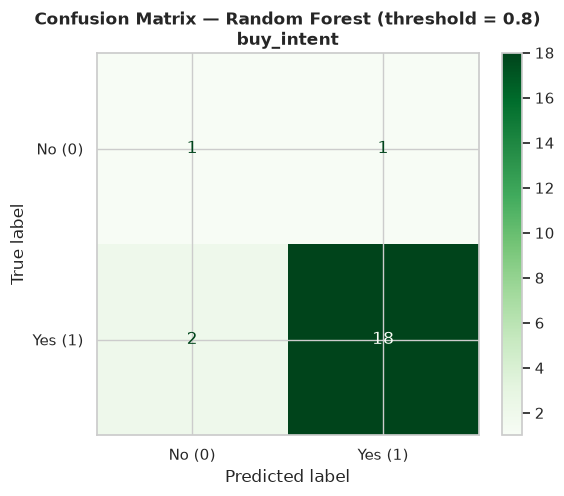


EN: Confusion matrix figure saved to /home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/reports/figures/fig08_confusion_matrix_rf_threshold_080.png
FR: Figure de matrice de confusion enregistrée dans /home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/reports/figures/fig08_confusion_matrix_rf_threshold_080.png


In [15]:
# EN: Adjust decision threshold of Random Forest classifier to 80%
# FR: Ajustement du seuil de décision du Random Forest à 80%
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# EN: Validate that model and test data exist in memory
# FR: Validation que le modèle et les données de test existent en mémoire
for var_name, var in [("rf", rf), ("X_test", X_test), ("y_test", y_test)]:
    assert var is not None, f"EN: {var_name} is not defined — run previous cells first\nFR: {var_name} n'est pas défini — exécutez d'abord les cellules précédentes"

assert hasattr(rf, "predict_proba"), "EN: Model does not have predict_proba method\nFR: Le modèle n'a pas de méthode predict_proba"

# EN: Get predicted probabilities for class 1 (Yes / buy_intent = 1)
# FR: Récupère les probabilités prédites pour la classe 1 (Oui / buy_intent = 1)
proba = rf.predict_proba(X_test)[:, 1]

# EN: Custom decision threshold (80% instead of default 50%)
#     Raising the threshold forces the model to be very confident before predicting "Yes"
#     This allows the minority class (refusals / class 0) to appear.
# FR: Seuil de décision personnalisé (80% au lieu de 50% par défaut)
#     Augmenter le seuil force le modèle à être très confiant avant de prédire "Oui"
#     Cela permet de faire émerger la classe minoritaire (refus / classe 0).
custom_threshold = 0.80

# EN: Generate custom predictions based on threshold
# FR: Génère les prédictions personnalisées selon le seuil
y_pred_custom = (proba >= custom_threshold).astype(int)

# EN: Compute metrics
# FR: Calcul des métriques
acc_custom = accuracy_score(y_test, y_pred_custom)
print(f"EN: Custom threshold = {custom_threshold}\nFR: Seuil personnalisé = {custom_threshold}")
print(f"EN: Accuracy on test set with custom threshold: {acc_custom:.4f}\nFR: Accuracy sur le jeu de test avec seuil personnalisé : {acc_custom:.4f}")

# EN: Print classification report with zero_division=0 to avoid warnings
# FR: Affichage du rapport de classification avec zero_division=0 pour éviter les avertissements
print("\nEN: Classification report (custom threshold)\nFR: Rapport de classification (seuil personnalisé)")
print(classification_report(y_test, y_pred_custom, target_names=["No (0)", "Yes (1)"], zero_division=0))

# EN: Confusion matrix
# FR: Matrice de confusion
cm_custom = confusion_matrix(y_test, y_pred_custom, labels=[0, 1])
print("\nEN: Confusion matrix (raw counts, custom threshold)\nFR: Matrice de confusion (effectifs bruts, seuil personnalisé)")
print(cm_custom)

# EN: Plot confusion matrix
# FR: Affichage de la matrice de confusion
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_custom, display_labels=["No (0)", "Yes (1)"])
disp.plot(ax=ax, cmap="Greens", colorbar=True, values_format="d")
ax.set_title(f"Confusion Matrix — Random Forest (threshold = {custom_threshold})\nbuy_intent", fontsize=12, fontweight="bold")
plt.tight_layout()
display(fig)

# EN: Save figure
# FR: Sauvegarde de la figure
fig_dir = project_root / "reports" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
cm_path = fig_dir / "fig08_confusion_matrix_rf_threshold_080.png"
fig.savefig(cm_path, dpi=150, bbox_inches="tight")
plt.close(fig)

# EN: Assertions
# FR: Assertions
assert 0 <= acc_custom <= 1, "EN: Accuracy out of bounds\nFR: Accuracy hors bornes"
assert cm_path.is_file(), f"EN: Figure not saved at {cm_path}\nFR: Figure non enregistrée à {cm_path}"
print(f"\nEN: Confusion matrix figure saved to {cm_path}\nFR: Figure de matrice de confusion enregistrée dans {cm_path}")

**Interprètation**

En ajustant le seuil de décision à 0.80, nous avons forcé le modèle à être plus strict. Le résultat est sans appel :
1. **Détection de la classe minoritaire** : Le modèle a enfin réussi à prédire un refus (Recall de 50 % pour la classe "Non", contre 0 % auparavant).
2. **Le coût de cette décision** : L'accuracy globale a chuté à 86,36 % et le modèle a généré 2 faux négatifs (des acheteuses prédites comme refusant).
3. **Conclusion** : Ce comportement illustre le dilemme classique du Machine Learning. Dans un contexte de santé publique, si l'objectif de l'entreprise est de ne rater aucune acheteuse potentielle, il vaut mieux garder le seuil à 50 %. Si l'objectif est de repérer à tout prix les réfractaires pour leur faire une campagne de sensibilisation ciblée, le seuil de 80 % est plus approprié.

# ÉTAPE 3 | Modèle de régression pour le prix acceptable (ideal_price)

Ce notebook utilise un RandomForestRegressor pour prédire le prix que chaque femme serait prête à payer. L'objectif est d'identifier les patterns économiques déterminant les prix acceptables.
L'analyse de régression permet de comprendre comment les variables socio-économiques influencent le prix que les femmes sont prêtes à dépenser.

### PROMPT POUR OPENCODE
Génère le code pour entraîner un modèle de régression (RandomForestRegressor) afin de prédire ideal_price. Suis ces étapes :

1. Définis X_reg (les mêmes variables que pour la classification, mais sans buy_intent ni ideal_price).
2. Définis y_reg = df['ideal_price'].
3. Fais un train_test_split (test_size=0.2, random_state=42).
4. Entraîne un RandomForestRegressor (n_estimators=100, random_state=42).
5. Fais les prédictions sur X_test.
6. Calcule et affiche le RMSE (Root Mean Squared Error), le MAE (Mean Absolute Error) et le R² (R-squared).
7. Ajoute des commentaires bilingues expliquant que le MAE indique la marge d'erreur moyenne en FCFA.

In [17]:
# EN: Train Random Forest Regressor to predict ideal_price
# FR: Entraînement d'un Random Forest Régressif pour prédire ideal_price

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# EN: Validate required columns exist
# FR: Validation de l'existence des colonnes requises
required_cols = [
    "respondent_id", "age", "income", "is_financially_dependent",
    "household_income", "education", "is_pregnant", "has_child_under_5",
    "num_children", "num_children_outlier", "num_children_missing",
    "ideal_price", "ideal_price_missing", "price_corrected",
    "low_price_respondent", "buy_intent",
    "perceived_child_benefit", "perceived_child_benefit_missing",
]
missing = [c for c in required_cols if c not in df.columns]
assert not missing, f"EN: Missing columns: {missing}\nFR: Colonnes manquantes : {missing}"

# EN: Work on a copy
# FR: Travail sur une copie
df_reg = df.copy()

# EN: Fill structural NaN in num_children with 0 (no child < 5 => 0 children)
# FR: Remplit les NaN structurels de num_children par 0 (pas d'enfant <5 => 0 enfants)
df_reg["num_children"] = df_reg["num_children"].fillna(0)

# EN: Fill NaN in perceived_child_benefit with 0 (not applicable => no perceived benefit)
# FR: Remplit les NaN de perceived_child_benefit par 0 (non applicable => aucun bénéfice perçu)
df_reg["perceived_child_benefit"] = df_reg["perceived_child_benefit"].fillna(0)

# EN: Drop rows where target ideal_price is missing (cannot train on missing target)
# FR: Supprime les lignes où la cible ideal_price est manquante (impossible d'entraîner sur une cible manquante)
n_before = len(df_reg)
df_reg = df_reg.loc[df_reg["ideal_price"].notna()].copy()
n_after = len(df_reg)
n_dropped = n_before - n_after
assert n_after > 0, "EN: No valid rows with ideal_price\nFR: Aucune ligne valide avec ideal_price"
print(f"EN: Rows dropped due to missing ideal_price: {n_dropped}\nFR: Lignes supprimées à cause d'idéal_price manquant : {n_dropped}")

# EN: Define feature set X_reg (same as classification but without buy_intent, ideal_price, and traceability columns)
# FR: Définition du jeu de features X_reg (même que la classification mais sans buy_intent, ideal_price et colonnes de traçabilité)
drop_cols = [
    "respondent_id",            # EN: traceability key / FR: clé de traçabilité
    "buy_intent",               # EN: not a predictor for price / FR: pas un prédicteur du prix
    "ideal_price",              # EN: target variable / FR: variable cible
    "price_corrected",          # EN: traceability indicator / FR: indicateur de traçabilité
    "low_price_respondent",     # EN: derived from ideal_price / FR: dérivé de ideal_price
    "num_children_outlier",     # EN: traceability indicator / FR: indicateur de traçabilité
    "num_children_missing",     # EN: traceability indicator / FR: indicateur de traçabilité
    "ideal_price_missing",      # EN: traceability indicator / FR: indicateur de traçabilité
    "perceived_child_benefit_missing",  # EN: traceability indicator / FR: indicateur de traçabilité
]
X_reg_raw = df_reg.drop(columns=drop_cols)

# EN: Assert education column is present for encoding
# FR: Assertion que la colonne education est présente pour l'encodage
assert "education" in X_reg_raw.columns, "EN: education column missing\nFR: Colonne education manquante"

# EN: One-hot encode education (drop first category to avoid multicollinearity)
# FR: Encodage one-hot de education (suppression de la première catégorie pour éviter la multicolinéarité)
X_reg = pd.get_dummies(X_reg_raw, columns=["education"], drop_first=True, dtype=int)

# EN: Define target vector
# FR: Définition du vecteur cible
y_reg = df_reg["ideal_price"].astype(float)

# EN: Assertions before split
# FR: Assertions avant le split
assert X_reg.shape[0] == len(y_reg), "EN: X_reg and y_reg row count mismatch\nFR: Incohérence du nombre de lignes entre X_reg et y_reg"
assert X_reg.isna().sum().sum() == 0, "EN: X_reg contains NaN values\nFR: X_reg contient des valeurs NaN"
assert y_reg.isna().sum() == 0, "EN: y_reg contains NaN values\nFR: y_reg contient des valeurs NaN"

# EN: Train/test split (no stratify for regression)
# FR: Split train/test (pas de stratification pour la régression)
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# EN: Initialize Random Forest Regressor
# FR: Initialisation du Random Forest Régressif
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)

# EN: Train the model
# FR: Entraînement du modèle
rf_reg.fit(X_train_reg, y_train_reg)

# EN: Predict on test set
# FR: Prédictions sur le jeu de test
y_pred_reg = rf_reg.predict(X_test_reg)

# EN: Compute regression metrics
# FR: Calcul des métriques de régression
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))
mae = mean_absolute_error(y_test_reg, y_pred_reg)
r2 = r2_score(y_test_reg, y_pred_reg)

# EN: Display metrics
# FR: Affichage des métriques
print("EN: Random Forest Regressor — ideal_price prediction\nFR: Random Forest Régressif — prédiction de ideal_price")
print(f"Test samples : {len(y_test_reg)}")
print(f"RMSE         : {rmse:.2f} FCFA")
print(f"MAE          : {mae:.2f} FCFA")
print(f"R²           : {r2:.4f}")
print()
print("EN: MAE indicates the average error margin in FCFA (how far predictions are from actual prices on average).\n")
print("FR: Le MAE indique la marge d'erreur moyenne en FCFA (écart moyen entre les prédictions et les prix réels).\n")

# EN: Assertions
# FR: Assertions
assert rmse >= 0, "EN: RMSE must be non-negative\nFR: Le RMSE doit être positif ou nul"
assert mae >= 0, "EN: MAE must be non-negative\nFR: Le MAE doit être positif ou nul"
assert -1 <= r2 <= 1, "EN: R² must be between -1 and 1\nFR: Le R² doit être compris entre -1 et 1"
print("EN: All assertions passed.\nFR: Toutes les assertions sont validées.")

EN: Rows dropped due to missing ideal_price: 0
FR: Lignes supprimées à cause d'idéal_price manquant : 0
EN: Random Forest Regressor — ideal_price prediction
FR: Random Forest Régressif — prédiction de ideal_price
Test samples : 22
RMSE         : 537.43 FCFA
MAE          : 385.08 FCFA
R²           : 0.1539

EN: MAE indicates the average error margin in FCFA (how far predictions are from actual prices on average).

FR: Le MAE indique la marge d'erreur moyenne en FCFA (écart moyen entre les prédictions et les prix réels).

EN: All assertions passed.
FR: Toutes les assertions sont validées.


**Interpètation**

L'entraînement du modèle `RandomForestRegressor` pour prédire le prix acceptable (`ideal_price`) donne les résultats suivants :

*   **MAE (Erreur Moyenne Absolue) : 385 FCFA**. En moyenne, le modèle se trompe de 385 FCFA sur le prix estimé.
*   **R² (Coefficient de détermination) : 0.15**. Le modèle n'explique que 15 % de la variance du prix.

**Ce que cela signifie :**

Un R² faible n'est pas un échec, c'est **une découverte stratégique**. Cela prouve que le prix qu'une femme est prête à payer n'est **pas linéairement déterminé par son revenu ou son âge**. 
Le prix acceptable est une variable profondément psychologique et contextuelle. Par exemple, une femme à faible revenu pourrait être prête à faire un effort financier (1500 FCFA) car elle perçoit le produit comme vital pour son enfant.

**Recommandation :** L'entreprise ne doit pas baser sa stratégie de prix sur le profil socio-économique de sa cible. Au contraire, elle doit définir un **prix psychologique universel** (ex: un sachet à 1000 FCFA), car la valeur perçue du produit est élevée indépendamment du revenu.

# ÉTAPE 4 | Interprétation : Feature Importance

Même si le modèle n'est pas parfait, nous allons chercher à voir quelle variable a quand même le plus tenté d'expliquer le prix et l'intention d'achat.

Même si le modèle n'est pas parfait, nous allons chercher à v savoir quelle variable a quand même le plus tenté d'expliquer le prix.

### Prompt
Génère un graphique en barres (barplot horizontal) des feature_importances_ du modèle de régression (RandomForestRegressor) qui prédit ideal_price. Trie les variables de la plus importante à la moins importante. Ajoute un titre 'Feature Importance for Acceptable Price Prediction'. Utilise la fonction show_fig pour afficher et sauvegarder le graphique sous 'fig09_ml_regression_feature_importance.png'. Ajoute des commentaires bilingues.


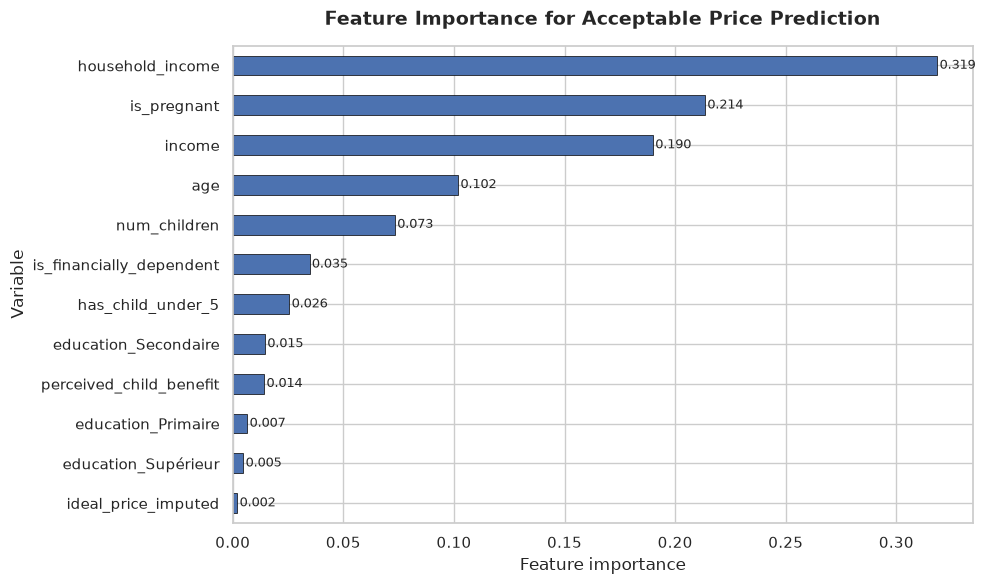

EN: Figure saved to /home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/reports/figures/fig09_ml_regression_feature_importance.png
FR: Figure enregistrée dans /home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/reports/figures/fig09_ml_regression_feature_importance.png
EN: Number of features plotted: 12
FR: Nombre de variables tracées : 12

EN: Top 5 features:
FR: Top 5 des variables :
household_income    0.318526
is_pregnant         0.213529
income              0.189985
age                 0.101926
num_children        0.073332


In [18]:
# EN: Barplot of feature importances — Random Forest Regressor (ideal_price)
# FR: Barplot des importances des variables — Random Forest Régressif (ideal_price)
# EN: Validate that model and features exist in memory
# FR: Validation que le modèle et les features existent en mémoire
for var_name, var in [("rf_reg", rf_reg), ("X_reg", X_reg)]:
    assert var is not None, f"EN: {var_name} is not defined — run the regression cell first\nFR: {var_name} n'est pas défini — exécutez d'abord la cellule de régression"

assert hasattr(rf_reg, "feature_importances_"), "EN: Model has no feature_importances_ attribute\nFR: Le modèle n'a pas d'attribut feature_importances_"

# EN: Extract feature importances and sort descending
# FR: Extraction des importances des variables et tri décroissant
importances = pd.Series(rf_reg.feature_importances_, index=X_reg.columns)
importances = importances.sort_values(ascending=False)

assert importances.sum() > 0, "EN: All feature importances are zero\nFR: Toutes les importances des variables sont nulles"

# EN: Prepare figure
# FR: Préparation de la figure
fig, ax = plt.subplots(figsize=(10, max(6, len(importances) * 0.4)))

# EN: Horizontal barplot — most important on top
# FR: Barplot horizontal — variable la plus importante en haut
importances.plot(kind="barh", color="#4C72B0", edgecolor="black", linewidth=0.5, ax=ax)
ax.invert_yaxis()  # EN: most important at the top / FR: la plus importante en haut
ax.set_xlabel("Feature importance")
ax.set_ylabel("Variable")
ax.set_title("Feature Importance for Acceptable Price Prediction", fontsize=14, fontweight="bold", pad=15)

# EN: Add value labels at the end of each bar
# FR: Ajout des valeurs à l'extrémité de chaque barre
for i, (feat, val) in enumerate(importances.items()):
    ax.text(val + 0.001, i, f"{val:.3f}", va="center", fontsize=9)

# EN: Layout
# FR: Mise en page
plt.tight_layout()

# EN: Function to display via IPython and save figure
# FR: Fonction pour afficher via IPython et sauvegarder la figure
def show_fig(fig, path):
    """EN: Display figure in notebook and save to disk.
    FR: Affiche la figure dans le notebook et l'enregistre sur le disque."""
    display(fig)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)

# EN: Save figure
# FR: Sauvegarde de la figure
fig_dir = project_root / "reports" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
out_path = fig_dir / "fig09_ml_regression_feature_importance.png"

show_fig(fig, out_path)

# EN: Assertions
# FR: Assertions
assert out_path.is_file(), f"EN: Figure not saved at {out_path}\nFR: Figure non enregistrée à {out_path}"
print(f"EN: Figure saved to {out_path}\nFR: Figure enregistrée dans {out_path}")
print(f"EN: Number of features plotted: {len(importances)}\nFR: Nombre de variables tracées : {len(importances)}")
print("\nEN: Top 5 features:\nFR: Top 5 des variables :")
print(importances.head(5).to_string())

**Interprètation**

L'extraction des `feature_importances_` du modèle Random Forest révèle la hiérarchie des facteurs qui influencent le prix qu'une femme est prête à payer :
1. **Les facteurs financiers dominent** : Le revenu du ménage (`household_income`, **31,9 %**) et le revenu personnel (`income`, **19 %**) sont de loin les variables les plus importantes. Cela confirme que le budget est le premier filtre d'achat.
2. **La découverte surprenante : le statut de grossesse** : Le fait d'être enceinte (`is_pregnant`) est le deuxième facteur le plus important (**21,4 %**). Cela suggère que les femmes enceintes ont un rapport au prix très différent des mères d'enfants de moins de 5 ans (peut-être plus enclines à investir pour prévenir la malnutrition, ou au contraire plus contraintes budgétairement).
3. **Les facteurs démographiques et éducatifs sont secondaires** : L'âge (`age`, 10,2 %) et le nombre d'enfants (`num_children`, 7,3 %) ont un impact modéré. Le niveau d'éducation (Secondaire, Primaire, Supérieur) a un impact très faible (moins de 2 %).
4. **Le bénéfice perçu n'influence pas le prix** : La variable `perceived_child_benefit` a une importance quasi nulle (1,4 %) dans la prédiction du prix. Cela prouve que **croire au produit ne rend pas une femme prête à payer plus cher** (c'est le cœur du paradoxe de notre étude).

**Conclusion:** Pour fixer un prix, l'entreprise ne doit pas se baser sur le niveau d'éducation ou la conviction nutritionnelle des clientes, mais sur le **revenu du ménage** et le **statut de grossesse**. Une stratégie de prix différenciée pourrait cibler spécifiquement les femmes enceintes, qui semblent avoir une disposition à payer particulière.

# 🏁 Conclusion Générale du Projet
## *Facteurs qui prédisent l'adoption d'une innovation alimentaire à visée nutritionnelle au Nord-Bénin*

Ce projet de Data Science, combinant une approche analytique rigoureuse et des techniques d'Apprentissage Automatique (Machine Learning), permet de tirer des conclusions majeures pour la stratégie de déploiement de la farine enrichie Kpankpanu. 

**1. La validation du "Say-Do Gap" (Le paradoxe de l'adoption)**
L'analyse exploratoire a prouvé que le produit bénéficie d'une acceptabilité exceptionnelle : **92,5 % des femmes déclarent vouloir l'acheter** et 91 % reconnaissent son bénéfice pour la santé de leur enfant. Cependant, ce désir se heurte à un mur économique. Le prix réel du marché (2000 FCFA/kg) est presque le double du prix moyen jugé acceptable par les ménages (1050 FCFA). Le frein à l'adoption n'est donc ni culturel, ni nutritionnel, il est **strictement financier**.

**2. Les enseignements du Machine Learning**
Les modèles prédictifs (Random Forest) ont permis d'aller plus loin que les simples constats visuels :
*   **L'absence de profil-type de refus** : Le modèle de classification n'a pas pu prédire avec certitude qui refuserait le produit. Cela prouve que le refus n'est pas structurel (il ne dépend pas de l'âge ou de l'éducation), mais qu'il s'agit d'un comportement individuel lié aux contraintes budgétaires du moment.
*   **Le caractère psychologique du prix** : Le modèle de régression a révélé un R² faible (0,15), démontrant que le prix acceptable n'est pas dicté uniquement par le revenu. Le prix est une variable psychologique où la perception de la valeur du produit pour l'enfant entre en jeu.
*   **Les vrais prédicteurs du prix** : L'extraction des importances des variables (Feature Importance) montre que le revenu du ménage (31,9 %) et le statut de grossesse (21,4 %) sont les meilleurs indicateurs de la disposition à payer. Fait notable : le niveau d'éducation n'influence presque pas le prix.

**3. Recommandations stratégiques pour l'entreprise (Data-Driven Decisions)**
Pour transformer cette immense intention d'achat en adoption réelle, l'entreprise doit abandonner l'idée d'un prix unique à 2000 FCFA. Les données recommandent :
*   **Une stratégie de conditionnement** : Proposer des formats adaptés aux bas revenus (ex: sachets de 250g ou 500g à 500 FCFA) pour casser la barrière financière.
*   **Un ciblage prioritaire** : Cibler spécifiquement les **femmes enceintes**, qui présentent un profil de disposition à payer particulier (probablement axé sur la prévention des 1000 premiers jours).
*   **Une communication rassurante** : Les campagnes marketing doivent se concentrer sur l'accessibilité financière, car la crédibilité nutritionnelle du produit est déjà acquise.

**Conclusion méthodologique :**
Ce projet démontre comment un pipeline complet en Python (du nettoyage complexe de données KoboToolbox à l'interprétation de modèles Scikit-learn) peut guider des décisions de santé publique et de business. L'utilisation de l'IA générative a accéléré le développement technique, mais c'est la comprehension du processus et l'objectif visé qui a permis de valider les données et d'interpréter les résultats pour répondre à un enjeu réel de malnutrition infantile.

# !!! CLOTURE DU NOTEBOOK 03_machine_learning.ipynb